# Predicting Peatland CH4 Emissions from Soil Conditions and Microbes

**Data Science course project – CH4 group (environmental data + metagenome genera)**

**Main question:** Does adding microbial data improve the prediction of CH4 emissions at *unseen* peatland sites beyond what soil conditions already predict?

The project study follows the 8-step pipeline of the project guideline. Every score shall be measured on **unseen sites** (cross-validation that keeps all stations of a site together).

## Libs & Setup

In [6]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.metrics import r2_score, mean_squared_error

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results")
RES_DIR.mkdir(exist_ok=True)

SEED = 42          # one fixed seed that we shall use
N_FOLDS = 10       # 10 fold cross-validation

# Colours
C_ENV = "#2a78d6"      # environmental predictors fixed colour
C_MIC = "#eb6834"      # microbial predictors
C_GEN = "#1baf7a"      # all genera
C_GREY = "#8c8b87"     # baseline colour
C_INK = "#2b2b2b"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e3",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#9a9a96",
    "axes.labelcolor": C_INK,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

## 1-Get to know the data

In [7]:
from google.colab import drive

drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/IDS-GroupProject/"

Mounted at /content/drive


In [8]:
df_raw     = pd.read_csv(DATA_DIR + "MIEF-PEAT_CH4_dataset_v0.csv")
dictionary = pd.read_csv(DATA_DIR + "CH4_data_dictionary_v0.csv")
genus_info = pd.read_csv(DATA_DIR + "CH4_genus_info_v0.csv")

ENV = ["pH", "von_post_grade", "organic_matter_frac", "soil_moisture_vwc",
       "P_mg_kg", "K_mg_kg", "Ca_mg_kg", "Mg_mg_kg", "nitrate_mg_kg", "ammonium_mg_kg",
       "total_N_pct", "total_C_pct", "CN_ratio", "water_table_cm",
       "soil_temp_10cm_C", "soil_temp_20cm_C"]
SHARE = ["methanogen_share_pct", "methanotroph_share_pct"]
GENUS = [c for c in df_raw.columns if c.startswith("genus_")]

print(f"Table: {df_raw.shape[0]} rows (stations) x {df_raw.shape[1]} columns")

print(f"Environmental variables: {len(ENV)} | share columns: {len(SHARE)} | genus columns: {len(GENUS)}")

print(f"Sites: {df_raw.site.nunique()} | stations per site: "
      f"{df_raw.groupby('site').size().min()}-{df_raw.groupby('site').size().max()}")

gi_groups = genus_info.CH4_group.value_counts()
print(f"Methanogen genera: {gi_groups.get('methanogen', 0)} | methanotroph genera: {gi_groups.get('methanotroph', 0)}")

Table: 196 rows (stations) x 241 columns
Environmental variables: 16 | share columns: 2 | genus columns: 210
Sites: 75 | stations per site: 1-8
Methanogen genera: 12 | methanotroph genera: 20


The raw dataset has no climate-zone column, so a climate zone is derived from the absolute latitude of each station (tropical < 23.5°, subtropical 23.5–35°, temperate 35–55°, boreal/subarctic ≥ 55°). This is a simple approximation used for this study.

,stations,sites
land_use,,
Fen,54,25
Pasture,40,16
Bog,36,14
Forest,30,8
Arable,22,8
Hay field,10,4
Peat extraction,4,2


,stations,sites
climate_zone,,
Tropical,56,20
Subtropical,17,7
Temperate,72,34
Boreal/subarctic,51,14


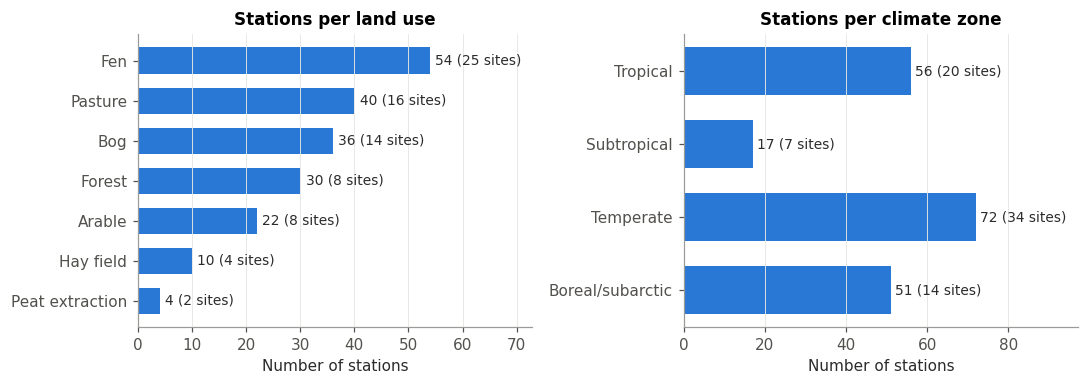

In [9]:
def climate_zone(lat):
    a = abs(lat)
    if a < 23.5: return "Tropical"
    if a < 35:   return "Subtropical"
    if a < 55:   return "Temperate"
    return "Boreal/subarctic"

df_raw["climate_zone"] = df_raw.latitude.apply(climate_zone) # new column to dataset => "climate_zone"

ZONES = ["Tropical", "Subtropical", "Temperate", "Boreal/subarctic"]

used_lands = ( df_raw.groupby("land_use").agg(stations=("station_id", "size"),  sites=("site", "nunique")).sort_values("stations", ascending=False) )
climate_zones = ( df_raw.groupby("climate_zone").agg(stations=("station_id", "size"), sites=("site", "nunique")).reindex(ZONES) )

display(used_lands)
display(climate_zones)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

for ax, tab, title in [(axes[0], used_lands, "Stations per land use"), (axes[1], climate_zones, "Stations per climate zone")]:

    ax.barh(tab.index[::-1], tab.stations[::-1], color=C_ENV, height=0.65)

    for i, (s, n) in enumerate(zip(tab.stations[::-1], tab.sites[::-1])):
        ax.text(s + 1, i, f"{s} ({n} sites)", va="center", fontsize=9, color=C_INK)

    ax.set_title(title); ax.set_xlabel("Number of stations"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, tab.stations.max() * 1.35)

fig.tight_layout()
savefig(fig, "fig01_stations_per_group")
plt.show()

***Let's check the if missing values exist or not in the raw dataset's envriomental columns.***

In [14]:
df_raw[ENV].isna().any()

,0
pH,True
von_post_grade,True
organic_matter_frac,False
soil_moisture_vwc,False
P_mg_kg,False
K_mg_kg,True
Ca_mg_kg,True
Mg_mg_kg,True
nitrate_mg_kg,False
ammonium_mg_kg,False


In [15]:
missing = df_raw[ENV].isna().sum().rename("missing").to_frame()

missing["percent"] = (100 * missing.missing / len(df_raw)).round(1)
display(missing.T)
print('**' * 30)

print("Stations with low sequencing depth (low_depth_flag, < 100,000 reads):")
display(df_raw.loc[df_raw.low_depth_flag, ["station_id", "site", "land_use", "kaiju_total_reads", "kaiju_genus_assigned_reads"]])

print('**' * 30)
print(f"Sequencing depth of the other stations: median {df_raw.loc[~df_raw.low_depth_flag, 'kaiju_total_reads'].median():,.0f} reads, +"
      f"min {df_raw.loc[~df_raw.low_depth_flag, 'kaiju_total_reads'].min():,.0f}")
print('**' * 30)
print(f"Stations with impossible soil moisture > 1 (moisture_above_1): {df_raw.moisture_above_1.sum()}")

,pH,von_post_grade,organic_matter_frac,soil_moisture_vwc,P_mg_kg,K_mg_kg,Ca_mg_kg,Mg_mg_kg,nitrate_mg_kg,ammonium_mg_kg,total_N_pct,total_C_pct,CN_ratio,water_table_cm,soil_temp_10cm_C,soil_temp_20cm_C
missing,8.0,21.0,0.0,0.0,0.0,8.0,8.0,8.0,0.0,0.0,1.0,0.0,1.0,3.0,0.0,0.0
percent,4.1,10.7,0.0,0.0,0.0,4.1,4.1,4.1,0.0,0.0,0.5,0.0,0.5,1.5,0.0,0.0


************************************************************
Stations with low sequencing depth (low_depth_flag, < 100,000 reads):


,station_id,site,land_use,kaiju_total_reads,kaiju_genus_assigned_reads
10,Y011,Iceland_drained_fen,Pasture,33084,6506.0
11,Y012,Iceland_drained_fen,Pasture,29520,5027.0
13,Y014,Iceland_drained_fen,Fen,2960,593.0
33,Y037,Bashkortostan_drained_floodplain_1,Hay field,21102,4021.0
79,Y083,Tasmania_blanket_bog,Bog,21804,4817.0


************************************************************
Sequencing depth of the other stations: median 13,434,049 reads, +min 196,230
************************************************************
Stations with impossible soil moisture > 1 (moisture_above_1): 13


***Let's take a closer look to the target feature***

In [16]:
ch4 = df_raw.CH4_ugC_m2_h # we took ch4(target feature) for examining in detail

print(f"CH4 flux (µg C m-2 h-1): {ch4.notna().sum()} measured, {ch4.isna().sum()} missing")
print('**' * 30)

print(f"  negative (uptake): {(ch4 < 0).sum()} stations, lowest = {ch4.min():.1f}")
print('**' * 30)

print(f"  median = {ch4.median():.1f}, mean = {ch4.mean():.1f}, max = {ch4.max():.1f}")
print('**' * 30)

print("Missing CH4:", ", ".join(df_raw.loc[ch4.isna(), "station_id"] + " (" + df_raw.loc[ch4.isna(), "site"] + ")"))
print('**' * 30)

print("--------------Five largest fluxes---------------")
display(df_raw.nlargest(5, "CH4_ugC_m2_h")[["station_id", "site", "land_use", "CH4_ugC_m2_h", "water_table_cm","soil_moisture_vwc"]])
print('**' * 30)

duplicated_fluxes = df_raw[df_raw.CH4_ugC_m2_h.notna() & (df_raw.CH4_ugC_m2_h != 0) & df_raw.CH4_ugC_m2_h.duplicated(keep=False)]
print("Non-zero fluxes that appear twice (same site):", ", ".join(duplicated_fluxes.station_id + " " + duplicated_fluxes.site))

CH4 flux (µg C m-2 h-1): 194 measured, 2 missing
************************************************************
  negative (uptake): 33 stations, lowest = -65.3
************************************************************
  median = 252.7, mean = 1794.8, max = 37907.6
************************************************************
Missing CH4: Y088 (Tasmania_raised_bog), Y121 (Tierra_del_Fuego_bog)
************************************************************
--------------Five largest fluxes---------------


,station_id,site,land_use,CH4_ugC_m2_h,water_table_cm,soil_moisture_vwc
174,Y177,Taiwan_recreation,Fen,37907.58139,-3.500000,0.937075
175,Y178,Taiwan_recreation,Fen,37907.58139,-3.500000,0.937075
140,Y144,Pantanal_pasture_3,Fen,26253.89840,0.000000,0.900000
143,Y146B,Khabarovsk_fen,Fen,25682.20611,-21.211712,0.771343
176,Y179,Taiwan_fen,Fen,20979.41162,0.000000,1.026000


************************************************************
Non-zero fluxes that appear twice (same site): Y177 Taiwan_recreation, Y178 Taiwan_recreation, Y179 Taiwan_fen, Y180 Taiwan_fen


## 2-Data Preparation

* **Target:** _log10(CH4 + 100)_.The provided column `CH4_log10_plus100` is re-computed from the raw flux and checked.

* **Missing CH4:** the 2 stations without a flux are removed.

* **Low-depth stations:** the 5 stations with ***low_depth_flag*** are removed from the main analysis *for all models*, so every model is scored on exactly the same stations

* **Genera:** read counts → relative abundance (divide by `kaiju_genus_assigned_reads`) and → _CLR_ (centred log-ratio). <br>Zeros are replaced by a pseudocount of 0.5 reads before the log. The CLR is computed per station from that station's own reads only, so it cannot leak information between sites.

* **Missing environmental values:** filled with the **median of the training sites only**, inside every cross-validation round (_SimpleImputer_ from scklearn was used).

* **moisture_above_1:** shall be kept in the main analysis (the stations are real, only the moisture value is doubtful)

In [17]:
# Relative abundance and CLR of the genera
counts = df_raw[GENUS].astype(float)

rel_abund = counts.div(df_raw.kaiju_genus_assigned_reads, axis=0)

log_cnts = np.log(counts + 0.5)

clr = log_cnts.sub(log_cnts.mean(axis=1), axis=0)

CLR = ["clr_" + c[len("genus_"):] for c in GENUS]
PROP = ["prop_" + c[len("genus_"):] for c in GENUS]

clr.columns, rel_abund.columns = CLR, PROP

base_df = pd.concat([df_raw, rel_abund, clr], axis=1)

base_df = base_df[base_df.CH4_ugC_m2_h.notna()].reset_index(drop=True)

def build_dataset(constant=100, include_low_depth=False, drop_moisture_above_1=False):
    df = base_df.copy()
    if not include_low_depth:
        df = df[~df.low_depth_flag]
    if drop_moisture_above_1:
        df = df[~df.moisture_above_1]

    df["y"] = np.log10(df.CH4_ugC_m2_h + constant)
    return df.reset_index(drop=True)

df_ch4 = build_dataset()

print('***' * 30)
print(f"Main modelling table: {len(df_ch4)} stations from {df_ch4.site.nunique()} sites")
print('***' * 30)
print(f"Predictors: 16 environmental, 2 share columns, {len(CLR)} genera (CLR)")
print('***' * 30)
print(f"Target log10(CH4+100): min {df_ch4.y.min():.2f}, median {df_ch4.y.median():.2f}, max {df_ch4.y.max():.2f}")

******************************************************************************************
Main modelling table: 189 stations from 75 sites
******************************************************************************************
Predictors: 16 environmental, 2 share columns, 210 genera (CLR)
******************************************************************************************
Target log10(CH4+100): min 1.74, median 2.56, max 4.58


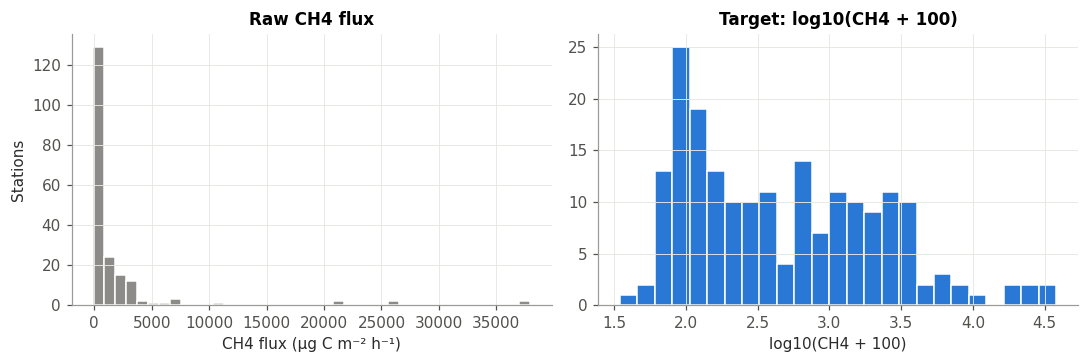

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

axes[0].hist(base_df.CH4_ugC_m2_h, bins=40, color=C_GREY, edgecolor="white")
axes[0].set_title("Raw CH4 flux")
axes[0].set_xlabel("CH4 flux (µg C m⁻² h⁻¹)")
axes[0].set_ylabel("Stations")

axes[1].hist(base_df.CH4_log10_plus100, bins=25, color=C_ENV, edgecolor="white")
axes[1].set_title("Target: log10(CH4 + 100)")
axes[1].set_xlabel("log10(CH4 + 100)")
fig.tight_layout()
savefig(fig, "fig02_target_transform")
plt.show()

Comments on the graphs;
* The raw flux is extremely skewed: most stations emit little and a few emit up to ~38,000 µg C m⁻² h⁻¹.
* On the log10(CH4 + 100) scale the values are spread between about 1.5 and 4.6, which a model can learn from.

## 3-Descriptive figures

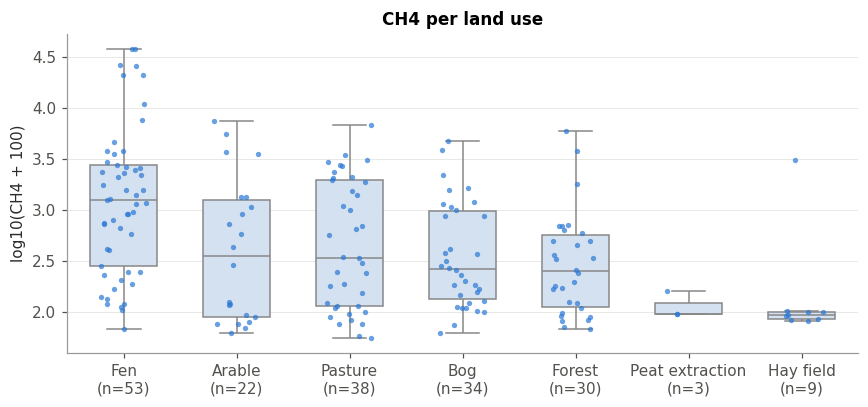

******************************************************************************************
******************************************************************************************


,count,median,min,max
land_use,,,,
Fen,53,3.10,1.83,4.58
Arable,22,2.55,1.79,3.87
Pasture,38,2.53,1.74,3.83
Bog,34,2.42,1.80,3.68
Forest,30,2.40,1.83,3.77
Peat extraction,3,1.98,1.98,2.20
Hay field,9,1.98,1.91,3.49


In [19]:
order_y_with_lu = df_ch4.groupby("land_use").y.median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 3.8))

sns.boxplot(data=df_ch4, x="land_use", y="y", order=order_y_with_lu, color="#cfe0f5", width=0.6, fliersize=0, linewidth=1, ax=ax)
sns.stripplot(data=df_ch4, x="land_use", y="y", order=order_y_with_lu, color=C_ENV, size=3.5, alpha=0.7, jitter=0.2, ax=ax)

counts_lu = df_ch4.land_use.value_counts()

ax.set_xticklabels([f"{l}\n(n={counts_lu[l]})" for l in order_y_with_lu])
ax.set_xlabel("")
ax.set_ylabel("log10(CH4 + 100)")
ax.set_title("CH4 per land use")
fig.tight_layout()
savefig(fig, "fig03_target_by_landuse")
plt.show()

print('***' * 30)
print('***' * 30)
display(df_ch4.groupby("land_use").y.agg(["count", "median", "min", "max"]).loc[order_y_with_lu].round(2))

`spearmanr` calculates the Spearman rank correlation between two variables. It measures whether, as one variable increases, the other also increases (or decreases) in a consistent manner.

<u>**How it works:**</u> It uses the ranks of the values rather than the values themselves. It sorts the values in each column from smallest to largest and assigns them the numbers 1, 2, 3…, then calculates the correlation between these rank numbers.

<u>**It returns two results:**</u>

rho (ρ): A value between −1 and +1.
If close to +1: as one increases, the other also increases.<br>
If close to −1: as one increases, the other decreases.<br>
If close to 0: there is no clear monotonic relationship.<br>

p-value: Indicates the probability that the relationship is due to chance.<br> Generally, if p < 0.05, the relationship is considered statistically significant.


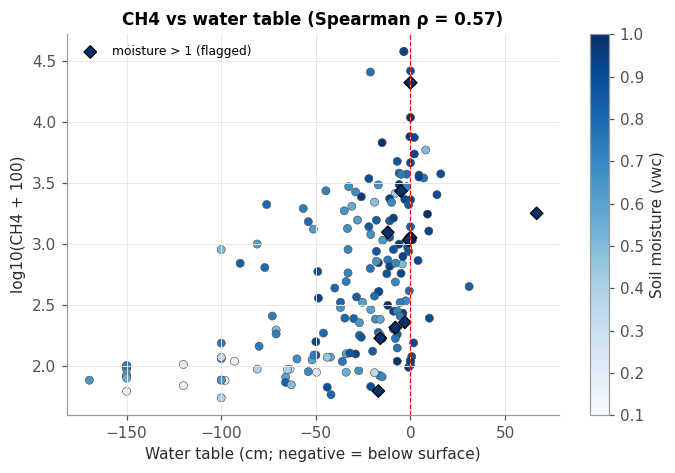

In [20]:
from scipy.stats import spearmanr
fig, ax = plt.subplots(figsize=(6.4, 4.4))

ok = ~df_ch4.moisture_above_1 # T/F vector for moisture case

sc = ax.scatter(df_ch4.water_table_cm[ok], df_ch4.y[ok], c=df_ch4.soil_moisture_vwc[ok], cmap="Blues", vmin=0.1, vmax=1.0, s=28, edgecolor="#52514e", linewidth=0.4)

ax.scatter(df_ch4.water_table_cm[~ok], df_ch4.y[~ok], c=df_ch4.soil_moisture_vwc[~ok].clip(upper=1), cmap="Blues",
           vmin=0.1, vmax=1.0, s=34, marker="D", edgecolor="black", linewidth=0.8, label="moisture > 1 (flagged)")

ax.axvline(0, color='red', lw=0.8, ls="--")

cb = fig.colorbar(sc, ax=ax)
cb.set_label("Soil moisture (vwc)")

rho, p = spearmanr(df_ch4.water_table_cm, df_ch4.y, nan_policy="omit")
ax.set_xlabel("Water table (cm; negative = below surface)")
ax.set_ylabel("log10(CH4 + 100)")
ax.set_title(f"CH4 vs water table (Spearman ρ = {rho:.2f})")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
savefig(fig, "fig04_target_vs_watertable")
plt.show()

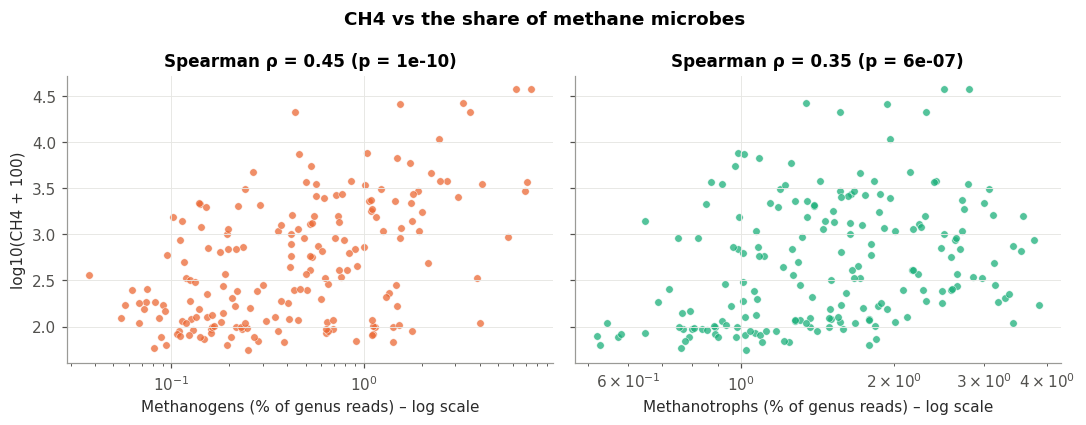

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)

for ax, col, color, label in [(axes[0], "methanogen_share_pct", C_MIC, "Methanogens (% of genus reads)"),
                              (axes[1], "methanotroph_share_pct", C_GEN, "Methanotrophs (% of genus reads)")]:

    ax.scatter(df_ch4[col], df_ch4.y, s=24, color=color, alpha=0.75, edgecolor="white", linewidth=0.4)

    rho, p = spearmanr(df_ch4[col], df_ch4.y)

    ax.set_xscale("log")
    ax.set_xlabel(label + " – log scale")
    ax.set_title(f"Spearman ρ = {rho:.2f} (p = {p:.1g})")

axes[0].set_ylabel("log10(CH4 + 100)")

fig.suptitle("CH4 vs the share of methane microbes", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig05_target_vs_microbes")
plt.show()

Comment on the figures;

* Stations with a larger share of methanogens emit clearly more CH4 (ρ = 0.45).
* Surprisingly, the methanotroph share is also *positively* related to CH4 (ρ = 0.35): methanotrophs grow where methane is available, so across sites they mark CH4-rich peat rather than low emissions.

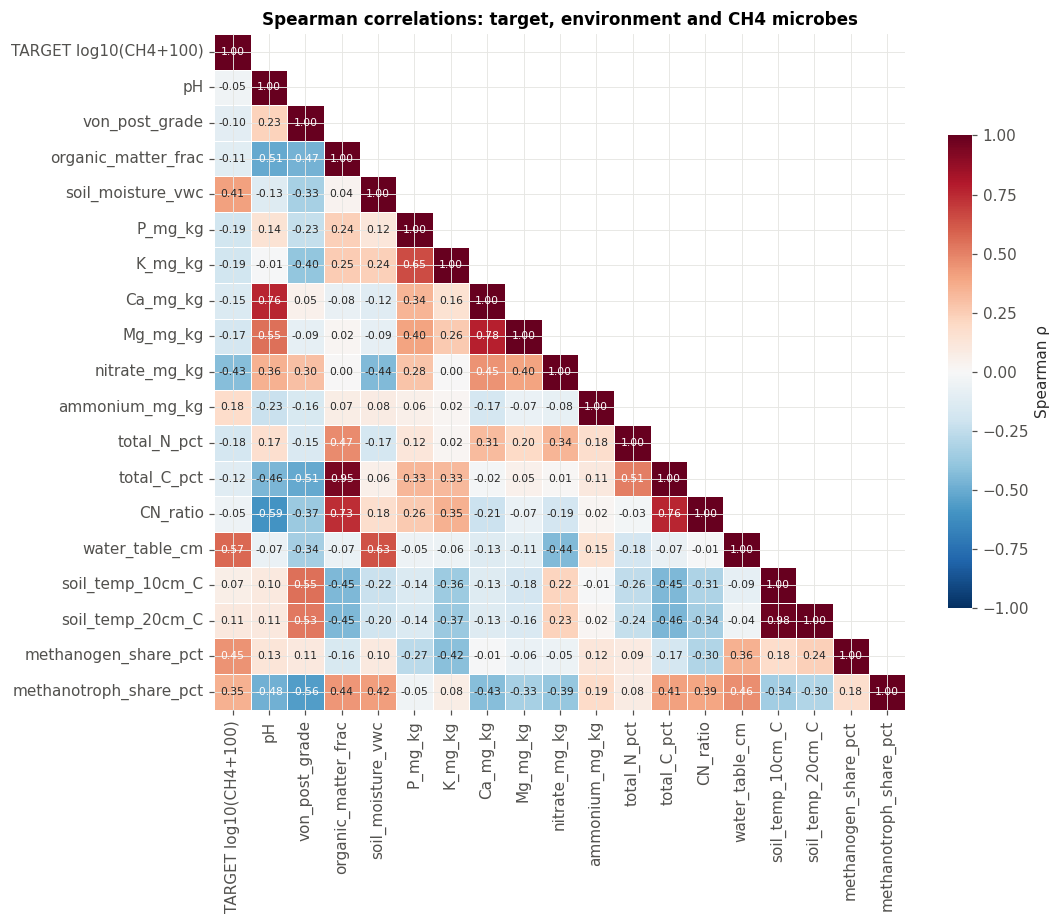

******************************************************************************************
******************************************************************************************


,water_table_cm,methanogen_share_pct,nitrate_mg_kg,soil_moisture_vwc,methanotroph_share_pct,K_mg_kg,P_mg_kg,ammonium_mg_kg,total_N_pct,Mg_mg_kg
ρ with target,0.57,0.45,-0.43,0.41,0.35,-0.19,-0.19,0.18,-0.18,-0.17


In [22]:
corr_cols = ["y"] + ENV + SHARE # correlations columns

# obtaining the correlations
corr = df_ch4[corr_cols].rename(columns={"y": "TARGET log10(CH4+100)"}).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8.5))

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, linecolor="white", cbar_kws={"label": "Spearman ρ", "shrink": 0.7}, ax=ax)

ax.set_title("Spearman correlations: target, environment and CH4 microbes")
fig.tight_layout()
savefig(fig, "fig06_correlation_heatmap")
plt.show()

print('***' * 30)
print('***' * 30)
# Target vs Columns Corr
target_corr = corr.iloc[1:, 0].sort_values(key=np.abs, ascending=False)
display(target_corr.round(2).to_frame("ρ with target").head(10).T)

Comments on the correlations;
*  The target correlates most with the water table (ρ = 0.57), the methanogen share (0.45), nitrate (−0.43, nitrate is high in drained, aerated peat), soil moisture (0.41) and the methanotroph share (0.35).
* Several predictors are correlated with each other (moisture–water table–organic matter–total C; the two soil temperatures; Ca–Mg–pH), so importance can be shared between them in the models.

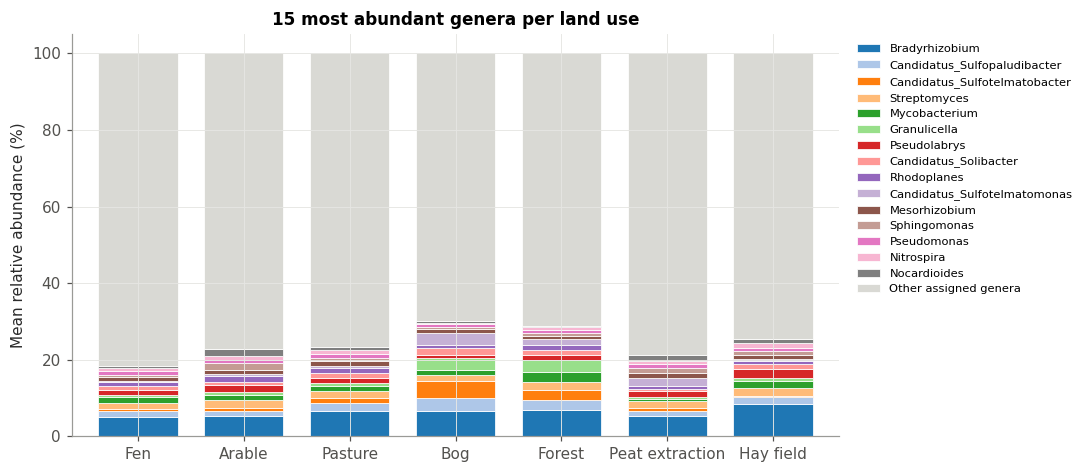

In [23]:
# 15 most abundant genera per land use
top15 = genus_info.sort_values("mean_rel_abundance_pct", ascending=False).genus.head(15).tolist()

rel_abnd = df_ch4[["land_use"] + ["prop_" + g for g in top15]].groupby("land_use").mean() * 100

rel_abnd.columns = top15

rel_abnd = rel_abnd.loc[order_y_with_lu]
rel_abnd["Other assigned genera"] = 100 - rel_abnd.sum(axis=1)

colr_pal = sns.color_palette("tab20", 15) + [(0.85, 0.85, 0.83)]

fig, ax = plt.subplots(figsize=(10, 4.4))

rel_abnd.plot(kind="bar", stacked=True, color=colr_pal, width=0.75, ax=ax, edgecolor="white", linewidth=0.5)
ax.set_ylabel("Mean relative abundance (%)")
ax.set_xlabel("")
ax.set_title("15 most abundant genera per land use")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=7.5)
plt.xticks(rotation=0)
fig.tight_layout()
savefig(fig, "fig07_top15_genera")
plt.show()

Comments on the Figure;
* The common genera (e.g. *Bradyrhizobium*, Acidobacteria such as *Candidatus* Sulfopaludibacter) are present everywhere
* Differences between land uses are gradual, so the community shifts with land use rather than being replaced.


## 4&5 - Cross-validation by site and the models

**Cross-validation design.** The 75 sites are split into 10 parts with `GroupKFold(shuffle=True)`; all stations of a site are always in the same part. *The same 10 rounds are used for every model*, so differences in score come only from the predictors.

In [24]:
# Site-grouped CV rounds
def cv_folds(df, seed=SEED, stratify=False, n_splits=N_FOLDS):
    X0 = np.zeros(len(df))

    if stratify:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        return list(cv.split(X0, df.land_use, groups=df.site))

    cv = GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    return list(cv.split(X0, groups=df.site))


def model_specs(genus_cols=CLR):
    imp = lambda: SimpleImputer(strategy="median")
    return {
        "Reference (mean)":            (["soil_moisture_vwc"], lambda: DummyRegressor(strategy="mean")),
        "Model 1 (soil moisture)":     (["soil_moisture_vwc"], lambda: make_pipeline(imp(), LinearRegression())),
        "Model 1b (water table)":      (["water_table_cm"],    lambda: make_pipeline(imp(), LinearRegression())),
    }

def cv_evaluate(make_model, X, y, folds):
    pred = np.full(len(y), np.nan)
    fold_rmse, fold_r2 = [], []

    for tr, te in folds:
        m = make_model()
        m.fit(X.iloc[tr], y[tr])
        preds = m.predict(X.iloc[te])
        pred[te] = preds
        fold_rmse.append(rmse(y[te], preds))
        fold_r2.append(r2_score(y[te], preds) if len(te) > 2 else np.nan)

    return {"pred": pred, "R2": r2_score(y, pred), "RMSE": rmse(y, pred),
            "fold_rmse": np.array(fold_rmse), "fold_r2": np.array(fold_r2)}

def run_models(df, folds, models=None, genus_cols=CLR):
    specs = model_specs(genus_cols)
    models = models or list(specs)
    y = df.y.to_numpy()
    out = {}

    for name in models:
        cols, curr_model = specs[name]
        out[name] = cv_evaluate(curr_model, df[cols], y, folds)
    return out

def score_table(res):
    rows = []

    for name, r in res.items():
        rows.append({"model": name, "R2": r["R2"], "RMSE": r["RMSE"],
                     "RMSE per round (mean)": r["fold_rmse"].mean(),
                     "RMSE spread (SD across rounds)": r["fold_rmse"].std(ddof=1),
                     "RMSE min-max": f"{r['fold_rmse'].min():.2f}-{r['fold_rmse'].max():.2f}"})

    return pd.DataFrame(rows).set_index("model")
#----------------------------------------------------------------------------
folds = cv_folds(df_ch4)

sizes = [len(np.unique(df_ch4.site.iloc[te])) for _, te in folds]

print(f"{len(folds)} rounds; test sites per round: {min(sizes)}-{max(sizes)}; "
      f"test stations per round: {min(len(te) for _, te in folds)}-{max(len(te) for _, te in folds)}")

10 rounds; test sites per round: 7-8; test stations per round: 14-25


In [25]:
results = run_models(df_ch4, folds)

scores = score_table(results)

scores.round(3).to_csv(RES_DIR / "model_scores_main.csv")
display(scores.round(3))

,R2,RMSE,RMSE per round (mean),RMSE spread (SD across rounds),RMSE min-max
model,,,,,
Reference (mean),-0.037,0.680,0.665,0.178,0.38-0.97
Model 1 (soil moisture),0.143,0.618,0.605,0.152,0.35-0.82
Model 1b (water table),0.232,0.585,0.573,0.139,0.31-0.78
